# Paso 17 · QFT en Python: una biblioteca paso a paso

Notebook del **Paso 17**: usar (y leer) `code/python/qftlib.py`, la biblioteca mínima de QFT del curso. No se usa ninguna toolbox de terceros.

| Función | Hace |
|---|---|
| `plant_family`, `template`, `boundary_indices` | familia de plantas, $P_i(j\omega)$ y plantas del borde |
| `spec_stability`, `spec_tracking`, `spec_disturbance`, `spec_noise` | fabrican una especificación (clausura) |
| `allowed_map` | mapa de bounds (fase × módulo) |
| `margin_db`, `check_L0` | margen de $L_0$ frente a los mapas |
| `shape_de`, `synthesize_refine` | loop shaping automático y refinado |
| `prefilter_search`, `verify` | prefiltro y verificación densa |
| `quad_*`, `exact_*` | bounds exactos |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

In [2]:
import inspect, time
from nbhelp import db, wrapfase, AZUL, NARANJA, TINTA, GRIS, VERDE
import qftlib as q            # nbhelp añade code/python al sys.path
print("biblioteca:", q.__file__)
print("funciones públicas:", [n for n, f in vars(q).items() if inspect.isfunction(f) and f.__module__ == q.__name__][:40])

biblioteca: /home/racarla96/Documents/GitHub/Quantitative_Feedback_Theory_Course/code/python/qftlib.py
funciones públicas: ['plant_family', 'template', 'boundary_indices', 'hull_indices', 'spec_stability', 'spec_tracking', 'spec_disturbance', 'spec_noise', 'allowed_map', 'margin_db', 'wrap_phase', 'check_L0', 'prefilter_search', 'verify', 'shape_de', 'synthesize_refine', 'quad_stability', 'quad_disturbance', 'quad_tracking_pairs', 'forbidden_intervals', 'exact_forbidden', 'exact_margin_db']


## 1. Familia y templates

La planta es una función de $(\omega,\theta)$; la familia, el producto cartesiano de rejillas de $\theta$.

In [3]:
print(inspect.getsource(q.plant_family)); print(inspect.getsource(q.template)); print(inspect.getsource(q.boundary_indices))
P = lambda w, K, a: K / (1j*w*(1j*w + a))
grids = [np.linspace(1, 5, 17), np.linspace(1, 3, 13)]
thetas = q.plant_family(grids)
idx = q.boundary_indices(thetas)
print(thetas.shape, "->", len(thetas), "plantas;", len(idx), "en el borde de la caja")

def plant_family(grids):
    """Producto cartesiano de rejillas de parametros -> lista de tuplas theta_i."""
    mesh = np.meshgrid(*grids, indexing="ij")
    return np.stack([m.ravel() for m in mesh], axis=1)

def template(Pfun, thetas, w):
    """P_i(jw) para todos los parametros (vector complejo de N elementos)."""
    return np.array([Pfun(w, *th) for th in thetas])

def boundary_indices(thetas):
    """Plantas con ALGUN parametro en un extremo de su rango (borde de la caja).
    Para estas especificaciones da el mismo mapa que usar toda la familia."""
    lo, hi = thetas.min(0), thetas.max(0)
    return np.where(((thetas == lo) | (thetas == hi)).any(axis=1))[0]

(221, 2) -> 221 plantas; 56 en el borde de la caja


## 2. Especificaciones como funciones

Una especificación es `f(L, w)` que recibe $L_i$ de todas las plantas (forma `[..., n_plantas]`) y devuelve `True` si se cumple. Se crean con una **clausura**:

In [4]:
print(inspect.getsource(q.spec_stability)); print(inspect.getsource(q.spec_tracking)); print(inspect.getsource(q.spec_disturbance))
Ws = 1.2
TU = lambda w: abs(1/((1j*w/8)**2 + 2*0.6*(1j*w/8) + 1)); TL = lambda w: abs(1/(1j*w/1.2 + 1)**3)
delta_db = lambda w: 20*np.log10(TU(w)/TL(w))
Wd = lambda w: 0.3 if w <= 0.5 else (0.5 if w <= 1.0 else 10.0)
specs = [q.spec_stability(Ws), q.spec_tracking(delta_db), q.spec_disturbance(Wd)]

def spec_stability(Ws):
    """|L/(1+L)| <= Ws  para todas las plantas."""
    return lambda L, w: np.all(np.abs(L / (1 + L)) <= Ws, axis=-1)

def spec_tracking(delta_db):
    """dispersion de |T_i| en dB <= delta_db(w): el prefiltro hara el resto."""
    def f(L, w):
        t = 20 * np.log10(np.abs(L / (1 + L)))
        return (t.max(-1) - t.min(-1)) <= delta_db(w)
    return f

def spec_disturbance(Wd):
    """|1/(1+L)| <= Wd(w)  (rechazo de perturbacion a la salida)."""
    return lambda L, w: np.all(1 / np.abs(1 + L) <= Wd(w), axis=-1)



## 3. El mapa de bounds

`allowed_map(w, ratios, specs, idx)` construye $L_0$ en la rejilla (fase × módulo), lo multiplica por los cocientes $r_i=P_i/P_0$ (*broadcasting*) y aplica todas las especificaciones.

def allowed_map(w, ratios, specs, idx=None, ph=PH, mg=MG):
    """Mapa booleano [len(ph), len(mg)]: True si L0 (fase ph, modulo mg dB)
    cumple TODAS las specs para las plantas del template (r_i = P_i / P_0).
    idx: subconjunto de plantas (None = todas)."""
    r = ratios if idx is None else ratios[idx]
    L0 = 10 ** (mg[None, :] / 20) * np.exp(1j * np.radians(ph)[:, None])
    L = L0[..., None] * r                      # forma [nph, nmg, N]
    ok = np.ones(L0.shape, bool)
    for s in specs:
        ok &= s(L, w)
    return ok



mapa en ω = 1: forma (360, 241), 33880 celdas permitidas, 465 ms


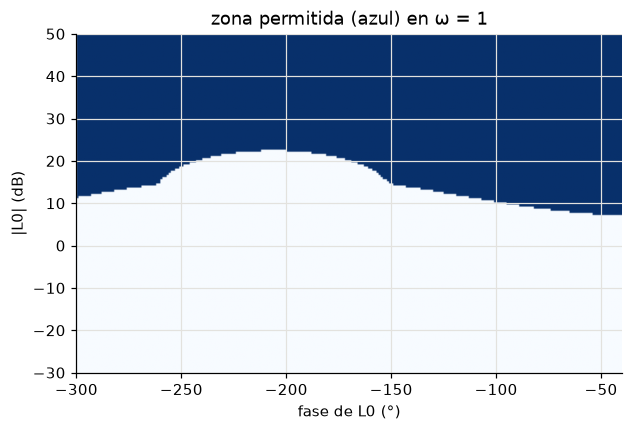

In [5]:
print(inspect.getsource(q.allowed_map))
w = 1.0
t0 = time.time(); m = q.allowed_map(w, q.template(P, thetas, w) / P(w, 1.0, 1.0), specs, idx=idx); dt = time.time() - t0
print(f"mapa en ω = 1: forma {m.shape}, {m.sum()} celdas permitidas, {dt*1e3:.0f} ms")

fig, ax = plt.subplots(figsize=(6.4, 4))
ax.imshow(m.T, origin="lower", aspect="auto", extent=[-360, 0, -60, 60], cmap="Blues")
ax.set_xlim(-300, -40); ax.set_ylim(-30, 50); ax.set_xlabel("fase de L0 (°)"); ax.set_ylabel("|L0| (dB)"); ax.set_title("zona permitida (azul) en ω = 1")
plt.show()

## 4. Margen y comprobación de $L_0$

In [6]:
print(inspect.getsource(q.margin_db))

def margin_db(okmap, phase, gain_db, ph=PH, mg=MG):
    """Distancia vertical (dB) al borde del mapa: >0 permitido, <0 prohibido."""
    dph = np.abs(((phase - ph + 180) % 360) - 180)   # diferencia en modulo 360
    i = int(np.argmin(dph))
    col = okmap[i]; j = int(np.argmin(np.abs(mg - gain_db)))
    bad = ~col if col[j] else col              # celdas del tipo contrario
    if not bad.any():
        return 60.0 if col[j] else -60.0
    d = np.abs(mg[bad] - gain_db).min()
    return d if col[j] else -d



`((phase - ph + 180) % 360) - 180` mide la diferencia de fase en módulo 360: $-359^\circ$ y $+1^\circ$ caen en la misma columna.

## 5. Ejemplo completo: el diseño del Paso 9

In [7]:
wlist = [0.1, 0.5, 1, 2, 5, 10, 20, 50]
maps = []
for w in wlist:
    z = q.template(P, thetas, w); r = z / P(w, 1.0, 1.0)
    maps.append(q.allowed_map(w, r, specs, idx=idx))

G9 = lambda s: 5*(1 + s/2)/(1 + s/20)
L0 = lambda w: G9(1j*w) * P(w, 1.0, 1.0)
marg = q.check_L0(L0, wlist, maps)
print("márgenes (dB):", np.round(marg, 2), "   (diapositivas: 6.45 0.79 0.93 17.94 60 60 5.54 16.12)")

wdense = np.logspace(-2, np.log10(60), 400)
Pfam = lambda w: q.template(P, thetas, w)
bad = q.verify(lambda w: G9(1j*w) * Pfam(w), wdense, specs)
print("verificación densa G9:", len(bad), "frecuencias fallan")
assert np.allclose(marg, [6.45, 0.79, 0.93, 17.94, 60, 60, 5.54, 16.12], atol=0.01)

márgenes (dB): [ 6.45  0.79  0.93 17.94 60.   60.    5.54 16.12]    (diapositivas: 6.45 0.79 0.93 17.94 60 60 5.54 16.12)
verificación densa G9: 0 frecuencias fallan


Los márgenes son positivos en las ocho frecuencias: $G=5\frac{1+s/2}{1+s/20}$ cumple los bounds (mínimo 0.79 dB en $\omega=0.5$). **60** significa «sin celdas prohibidas en esa fase» (valor truncado).

## 6. Loop shaping automático y refinado

In [8]:
print(inspect.getsource(q.shape_de)); print(inspect.getsource(q.synthesize_refine))

def shape_de(P0fun, wlist, maps, bounds=((0.5, 30), (0.2, 20), (2, 200)),
             seed=1, maxiter=60):
    """Busca (k, z, p) que cumple los mapas con el menor G(inf) = k p / z
    (menos ruido en alta frecuencia)."""
    def cost(x):
        k, z, p = x
        G = lambda s: k * (1 + s / z) / (1 + s / p)
        m = check_L0(lambda w: G(1j * w) * P0fun(w), wlist, maps)
        pen = np.sum(np.clip(-m, 0, None))                       # dB de violacion
        return k * p / z + 1e3 * pen
    r = differential_evolution(cost, bounds, seed=seed, maxiter=maxiter,
                               tol=1e-6, polish=False)
    return r.x, r.fun

def synthesize_refine(P0fun, Pfam, specs, wlist, wdense, make_map,
                      bounds=((0.5, 30), (0.2, 20), (2, 200)), iters=8, add=3):
    """Bucle de refinado: DE con los mapas actuales -> verificacion densa
    -> anadir frecuencias que fallan -> repetir.
    make_map(w) -> mapa permitido a la frecuencia w.  Devuelve (x, historial)."""

In [9]:
P0 = lambda w: P(w, 1.0, 1.0)
make_map = lambda w: q.allowed_map(w, Pfam(w) / P0(w), specs, idx=idx)
t0 = time.time(); x, hist = q.synthesize_refine(P0, Pfam, specs, wlist, wdense, make_map)
print(f"{'k':>7} {'z':>7} {'p':>7} {'G(inf)':>8} {'fallos':>7} {'n_w':>5}")
for xx, ginf, nbad, nw in hist: print(f"{xx[0]:7.3f} {xx[1]:7.3f} {xx[2]:7.3f} {ginf:8.2f} {nbad:7d} {nw:5d}")
print(f"{time.time() - t0:.1f} s ; diseño final k={x[0]:.3f}, z={x[1]:.3f}, p={x[2]:.2f}, G(∞)={hist[-1][1]:.1f} (a mano: 50)")

      k       z       p   G(inf)  fallos   n_w
  5.002   2.216  13.095    29.55      33     8
  5.129   2.650  16.579    32.08      16    11
  5.084   2.467  16.070    33.12       6    14
  5.103   2.541  16.564    33.27       1    17
  5.099   2.537  16.533    33.23       1    18
  4.714   2.107  14.791    33.09       1    19
  4.714   2.107  14.791    33.09       1    20
  5.095   2.521  16.425    33.19       0    21
19.7 s ; diseño final k=5.095, z=2.521, p=16.43, G(∞)=33.2 (a mano: 50)


El bucle insiste hasta que la verificación densa pasa; añadir frecuencias **no** garantiza converger en una vuelta (las iteraciones 4–7 siguen con 1 fallo). Frente a $G(\infty)=50$ del diseño a mano, el automático necesita ≈ 33.

## 7. Prefiltro y verificación

In [10]:
Tfam = lambda w: np.abs((lambda L: L/(1 + L))(G9(1j*w)*Pfam(w)))
mg, f = q.prefilter_search(Tfam, TU, TL, np.logspace(-1, np.log10(40), 60), np.arange(0.5, 3.01, 0.1))
print(f"G del paso 9: prefiltro f = {f:.1f}, margen = {mg:.3f} dB (diapositivas: f = 1.1, 0.028 dB)")
Gauto = lambda s: x[0]*(1 + s/x[1])/(1 + s/x[2])
Tfa = lambda w: np.abs((lambda L: L/(1 + L))(Gauto(1j*w)*Pfam(w)))
mg2, f2 = q.prefilter_search(Tfa, TU, TL, np.logspace(-1, np.log10(40), 60), np.arange(0.5, 3.01, 0.1))
print(f"G automático: prefiltro f = {f2:.1f}, margen = {mg2:.3f} dB")

G del paso 9: prefiltro f = 1.1, margen = 0.028 dB (diapositivas: f = 1.1, 0.028 dB)


G automático: prefiltro f = 1.0, margen = 0.032 dB


## 8. Las pruebas (`test_qft.py`)

Cuatro pruebas independientes dicen si algo se rompió al tocar el código: **(1)** el borde da el mismo mapa que toda la familia (la envolvente no); **(2)** la fórmula cerrada coincide con la rejilla; **(3)** el diseño del Paso 9 pasa la verificación densa; **(4)** los bounds exactos coinciden con la rejilla. Ejecutémoslas desde el notebook:

In [11]:
import subprocess, sys, os
res = subprocess.run([sys.executable, "test_qft.py"], cwd=os.path.dirname(q.__file__), capture_output=True, text=True)
print(res.stdout[-1400:] or res.stderr[-800:])

w=  0.1: borde    0 celdas erroneas | hull   21
w=    1: borde    0 celdas erroneas | hull    3
w=    2: borde    0 celdas erroneas | hull  263
w=    5: borde    0 celdas erroneas | hull  261
w=   20: borde    0 celdas erroneas | hull  260
w=1.0: formula cerrada vs rejilla, celdas distintas = 0
w=2.0: formula cerrada vs rejilla, celdas distintas = 0
verificacion densa: frecuencias que fallan = 0
w=0.5: exacto vs rejilla, celdas distintas = 0; margen exacto = 0.701 dB
w=1.0: exacto vs rejilla, celdas distintas = 0; margen exacto = 0.627 dB
w=2.0: exacto vs rejilla, celdas distintas = 0; margen exacto = 17.673 dB



## 9. Rendimiento y cómo extenderlo

- Un mapa con 56 plantas ≈ 0.2–0.4 s; la búsqueda de refinado, ~20 s (la mayor parte es `verify`, no vectorizada).
- **Menos memoria**: fase por bloques, `complex64`. **Más rápido**: `numba`, vectorizar `verify` sobre $\omega$, `multiprocessing` (los mapas de cada $\omega$ son independientes).
- **Extender**: otra planta ⇒ otra función `P(w, *theta)`; otra especificación ⇒ otra clausura `f(L, w)`; discreto ⇒ `P` evaluada en $e^{j\omega T_s}$.

## 10. Ejercicio del Paso 17

1. Añade `spec_noise(-10)` en $\omega\ge30$ y comprueba si el diseño del Paso 9 sigue pasando. 2. ¿Qué cambia en `template` para **medir** la planta en vez de usar una fórmula? 3. ¿Qué pasa con la memoria si pasas a 1000 plantas?

**Tu turno.**

In [12]:
# 1) specs2 = specs + [una función que aplique q.spec_noise(-10) solo si w >= 30]
# 2) piensa en qué entra a template   3) calcula 360*241*N*16 bytes
# escribe aquí tu código

In [13]:
ruido = q.spec_noise(-10)
solo_alta = lambda L, w: ruido(L, w) if w >= 30 else np.ones(L.shape[:-1], bool)
bad2 = q.verify(lambda w: G9(1j*w) * Pfam(w), wdense, specs + [solo_alta])
print(f"1) con ruido |T| ≤ -10 dB en ω ≥ 30: {len(bad2)} frecuencias fallan"
      + (f" (la primera, ω = {bad2.min():.1f})" if len(bad2) else "  -> el diseño del paso 9 SIGUE pasando"))
print("2) template deja de llamar a Pfun y devuelve las respuestas medidas a esa ω (un vector complejo por experimento);")
print("   boundary_indices se sustituye por todos los puntos o por su envolvente (sin la garantía del borde).")
for N in (56, 1000): print(f"3) N = {N:>4}: la matriz 3D ocupa {360*241*N*16/1e6:,.0f} MB -> con 1000 plantas hay que procesar la fase por bloques")

1) con ruido |T| ≤ -10 dB en ω ≥ 30: 0 frecuencias fallan  -> el diseño del paso 9 SIGUE pasando
2) template deja de llamar a Pfun y devuelve las respuestas medidas a esa ω (un vector complejo por experimento);
   boundary_indices se sustituye por todos los puntos o por su envolvente (sin la garantía del borde).
3) N =   56: la matriz 3D ocupa 78 MB -> con 1000 plantas hay que procesar la fase por bloques
3) N = 1000: la matriz 3D ocupa 1,388 MB -> con 1000 plantas hay que procesar la fase por bloques


## 11. Resumen

- `qftlib.py` implementa el flujo completo en unos pocos cientos de líneas: familia → templates → especificaciones → mapas → loop shaping → prefiltro → verificación (+ bounds exactos).
- Está **probado** (4 pruebas) y reproduce los números del curso.
- Es la base del Paso 18 (la misma biblioteca en MATLAB/Octave).